In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import warnings
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                           roc_auc_score, classification_report, confusion_matrix, roc_curve)
import pickle

warnings.filterwarnings('ignore')
plt.rcParams['font.size'] = 12
plt.rcParams['figure.figsize'] = (10, 6)
PLOTS_DIR = "../static/plots"
os.makedirs(PLOTS_DIR, exist_ok=True)
np.random.seed(42)

Rozmiar zbioru: (88647, 112)
Liczba cech: 111

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['qty_redirects', 'url_google_index', 'domain_google_index', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bez phisingowe: 58,000 (65.4%)
URL oznaczone jako phisingowe: 30,647 (34.6%)


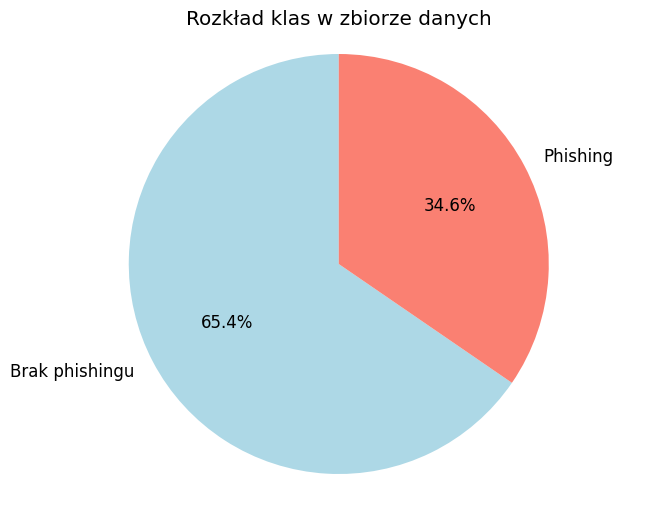


Informacje o zbiorze:
- Łączna liczba próbek: 88,647
- Liczba cech: 111
- Brakujące wartości: 0
- Duplikaty: 1438

Dostępne cechy: 100
Przykładowe cechy: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url', 'qty_equal_url', 'qty_at_url', 'qty_and_url', 'qty_exclamation_url', 'qty_space_url']
- Duplikaty: 1438

Dostępne cechy: 100
Przykładowe cechy: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url', 'qty_equal_url', 'qty_at_url', 'qty_and_url', 'qty_exclamation_url', 'qty_space_url']


In [7]:
df = pd.read_csv('../data/dataset_full.csv')

print(f"Rozmiar zbioru: {df.shape}")
print(f"Liczba cech: {len(df.columns)-1}")

print(f"\nPierwsze 5 kolumn: {list(df.columns[:5])}")
print(f"Ostatnie 5 kolumn: {list(df.columns[-5:])}")

label_counts = df['phishing'].value_counts()
print(f"\nRozkład etykiet:")
print(f"URL oznaczone jako bez phisingowe: {label_counts[0]:,} ({label_counts[0]/len(df)*100:.1f}%)")
print(f"URL oznaczone jako phisingowe: {label_counts[1]:,} ({label_counts[1]/len(df)*100:.1f}%)")

plt.figure(figsize=(8, 6))
colors = ['lightblue', 'salmon']
labels = ['Brak phishingu', 'Phishing']
plt.pie(label_counts.values, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Rozkład klas w zbiorze danych')
plt.axis('equal')
plt.show()

print(f"\nInformacje o zbiorze:")
print(f"- Łączna liczba próbek: {len(df):,}")
print(f"- Liczba cech: {len(df.columns)-1}")
print(f"- Brakujące wartości: {df.isnull().sum().sum()}")
print(f"- Duplikaty: {df.duplicated().sum()}")

network_dependent_features = [
    'time_response', 'domain_spf', 'asn_ip', 'time_domain_activation', 
    'time_domain_expiration', 'qty_ip_resolved', 'qty_nameservers', 
    'qty_mx_servers', 'ttl_hostname', 'url_google_index', 'domain_google_index'
]

feature_columns = [col for col in df.columns if col != 'phishing' and col not in network_dependent_features]
print(f"\nDostępne cechy: {len(feature_columns)}")
print(f"Przykładowe cechy: {feature_columns[:10]}")

In [8]:
network_dependent_features = [
    'time_response', 'domain_spf', 'asn_ip', 'time_domain_activation', 
    'time_domain_expiration', 'qty_ip_resolved', 'qty_nameservers', 
    'qty_mx_servers', 'ttl_hostname', 'url_google_index', 'domain_google_index'
]

feature_columns = [col for col in df.columns if col != 'phishing' and col not in network_dependent_features]
X = df[feature_columns]
y = df['phishing']          

print(f"\nTypy danych cech:")
data_types = X.dtypes.value_counts()
for dtype, count in data_types.items():
    print(f"  {dtype}: {count} kolumn")

inf_count = np.isinf(X.select_dtypes(include=[np.number])).sum().sum()
nan_count = X.isnull().sum().sum()

print(f"  Wartości nieskończone: {inf_count}")
print(f"  Wartości brakujące: {nan_count}")

if inf_count > 0:
    print("Wykryto wartości nieskończone - zastępowanie medianą...")
    X = X.replace([np.inf, -np.inf], np.nan)

if X.isnull().sum().sum() > 0:
    print("Wykryto wartości brakujące - zastępowanie medianą...")
    X = X.fillna(X.median())

print(f"\nStatystyki cech przed skalowaniem:")
X_num = X.select_dtypes(include=[np.number])
print(f"  Minimum: {X_num.min().min():.4f}")
print(f"  Maksimum: {X_num.max().max():.4f}")
print(f"  Średnia: {X_num.mean().mean():.4f}")
print(f"  Odchylenie standardowe: {X_num.std().mean():.4f}")


Typy danych cech:
  int64: 100 kolumn
  Wartości nieskończone: 0
  Wartości brakujące: 0

Statystyki cech przed skalowaniem:
  Minimum: -1.0000
  Maksimum: 4165.0000
  Średnia: 0.5481
  Wartości nieskończone: 0
  Wartości brakujące: 0

Statystyki cech przed skalowaniem:
  Minimum: -1.0000
  Maksimum: 4165.0000
  Średnia: 0.5481
  Odchylenie standardowe: 1.7407
  Odchylenie standardowe: 1.7407


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Zbiór uczący: {X_train.shape[0]:,} próbek ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Zbiór testowy: {X_test.shape[0]:,} próbek ({X_test.shape[0]/len(X)*100:.1f}%)")

print(f"\nRozkład klas w zbiorze uczącym:")
train_counts = y_train.value_counts()
print(f"  Brak phishingu: {train_counts[0]:,} ({train_counts[0]/len(y_train)*100:.1f}%)")
print(f"  Phishing: {train_counts[1]:,} ({train_counts[1]/len(y_train)*100:.1f}%)")

print(f"\nRozkład klas w zbiorze testowym:")
test_counts = y_test.value_counts()
print(f"  Brak phishingu: {test_counts[0]:,} ({test_counts[0]/len(y_test)*100:.1f}%)")
print(f"  Phishing: {test_counts[1]:,} ({test_counts[1]/len(y_test)*100:.1f}%)")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nStatystyki cech po skalowaniu (zbiór uczący):")
print(f"  Średnia: {X_train_scaled.mean():.6f}")
print(f"  Odchylenie standardowe: {X_train_scaled.std():.6f}")
print(f"  Minimum: {X_train_scaled.min():.4f}")
print(f"  Maksimum: {X_train_scaled.max():.4f}")

Zbiór uczący: 70,917 próbek (80.0%)
Zbiór testowy: 17,730 próbek (20.0%)

Rozkład klas w zbiorze uczącym:
  Brak phishingu: 46,400 (65.4%)
  Phishing: 24,517 (34.6%)

Rozkład klas w zbiorze testowym:
  Brak phishingu: 11,600 (65.4%)
  Phishing: 6,130 (34.6%)

Statystyki cech po skalowaniu (zbiór uczący):

Statystyki cech po skalowaniu (zbiór uczący):
  Średnia: 0.000000
  Odchylenie standardowe: 0.932738
  Minimum: -4.0788
  Maksimum: 266.3006
  Średnia: 0.000000
  Odchylenie standardowe: 0.932738
  Minimum: -4.0788
  Maksimum: 266.3006


In [10]:

param_grids = [
    {
        'name': 'Jądro liniowe',
        'params': {
            'C': [0.1, 1, 10, 100],
            'kernel': ['linear'],
            'gamma': ['scale', 'auto']
        }
    },
    {
        'name': 'Jądro RBF (radialne)',
        'params': {
            'C': [0.1, 1, 10, 100],
            'kernel': ['rbf'],
            'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
        }
    },
    {
        'name': 'Jądro wielomianowe',
        'params': {
            'C': [0.1, 1, 10, 100, 1000],
            'kernel': ['poly'],
            'degree': [2, 3, 4],
            'gamma': ['scale', 'auto']
        }
    }
]

best_overall_score = 0
best_overall_model = None
best_overall_params = None
best_kernel_name = ""

subset_size = min(15000, len(X_train_scaled))  

start_time = time.time()

for i, grid_config in enumerate(param_grids):
    kernel_name = grid_config['name']
    param_grid = grid_config['params']
    
    print(f"\n--- Test {i+1}/{len(param_grids)}: {kernel_name} ---")
    
    combinations = 1
    for param_values in param_grid.values():
        combinations *= len(param_values)
    print(f"Liczba kombinacji do przetestowania: {combinations}")
    
    grid_start_time = time.time()
    
    np.random.seed(42)
    indices = np.random.choice(len(X_train_scaled), subset_size, replace=False)
    X_subset = X_train_scaled[indices]
    y_subset = y_train.iloc[indices]
    
    grid_search = GridSearchCV(
        estimator=SVC(
            random_state=42, 
            probability=True,  
            cache_size=1000    
        ),
        param_grid=param_grid,
        cv=3,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0
    )
    
    grid_search.fit(X_subset, y_subset)
    
    grid_time = time.time() - grid_start_time
    
    print(f"Czas wykonania: {grid_time:.2f} sekund")
    print(f"Najlepszy wynik CV ROC-AUC: {grid_search.best_score_:.4f}")
    print(f"Najlepsze parametry: {grid_search.best_params_}")
    
    if grid_search.best_score_ > best_overall_score:
        best_overall_score = grid_search.best_score_
        best_overall_model = grid_search.best_estimator_
        best_overall_params = grid_search.best_params_
        best_kernel_name = kernel_name
        print(f"Nowy najlepszy model: {kernel_name}")

best_model = best_overall_model
print(f"Najlepsze jądro: {best_kernel_name}")
print(f"Najlepsze parametry: {best_overall_params}")

final_training_start = time.time()

best_model.fit(X_train_scaled, y_train)

final_training_time = time.time() - final_training_start
total_time = time.time() - start_time

print(f"Finalne uczenie zakończone w {final_training_time:.2f} sekund")
print(f"Całkowity czas strojenia i uczenia: {total_time:.2f} sekund ({total_time/60:.1f} minut)")


--- Test 1/3: Jądro liniowe ---
Liczba kombinacji do przetestowania: 8
Czas wykonania: 3996.96 sekund
Najlepszy wynik CV ROC-AUC: 0.9648
Najlepsze parametry: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Nowy najlepszy model: Jądro liniowe

--- Test 2/3: Jądro RBF (radialne) ---
Liczba kombinacji do przetestowania: 24
Czas wykonania: 3996.96 sekund
Najlepszy wynik CV ROC-AUC: 0.9648
Najlepsze parametry: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Nowy najlepszy model: Jądro liniowe

--- Test 2/3: Jądro RBF (radialne) ---
Liczba kombinacji do przetestowania: 24
Czas wykonania: 666.89 sekund
Najlepszy wynik CV ROC-AUC: 0.9673
Najlepsze parametry: {'C': 1, 'gamma': 0.001, 'kernel': 'rbf'}
Nowy najlepszy model: Jądro RBF (radialne)

--- Test 3/3: Jądro wielomianowe ---
Liczba kombinacji do przetestowania: 30
Czas wykonania: 666.89 sekund
Najlepszy wynik CV ROC-AUC: 0.9673
Najlepsze parametry: {'C': 1, 'gamma': 0.001, 'kernel': 'rbf'}
Nowy najlepszy model: Jądro RBF (radialne)

---

Przeprowadzanie walidacji krzyżowej...

Dokładność:     0.9124 (91.24%)
Precyzja:       0.8667 (86.67%)
Czułość:        0.8824 (88.24%)
Miara F1:       0.8745
ROC-AUC:        0.9665
CV ROC-AUC:     0.9681 (±0.0019)
                    precision    recall  f1-score   support

Bez phisingowe URL       0.94      0.93      0.93     11600
   Phishingowe URL       0.87      0.88      0.87      6130

          accuracy                           0.91     17730
         macro avg       0.90      0.91      0.90     17730
      weighted avg       0.91      0.91      0.91     17730


Analiza macierzy pomyłek:
  Prawdziwie negatywne (TN): 10,768
  Fałszywie pozytywne (FP): 832
  Fałszywie negatywne (FN): 721
  Prawdziwie pozytywne (TP): 5,409

Informacje o modelu SVM:
  Jądro: rbf
  Parametr C: 1
  Parametr gamma: 0.001
  Stopień wielomianu: 3
  Liczba wektorów nośnych: 16,547
  Procent wektorów nośnych: 23.33%

Dokładność:     0.9124 (91.24%)
Precyzja:       0.8667 (86.67%)
Czułość:        0.8824 

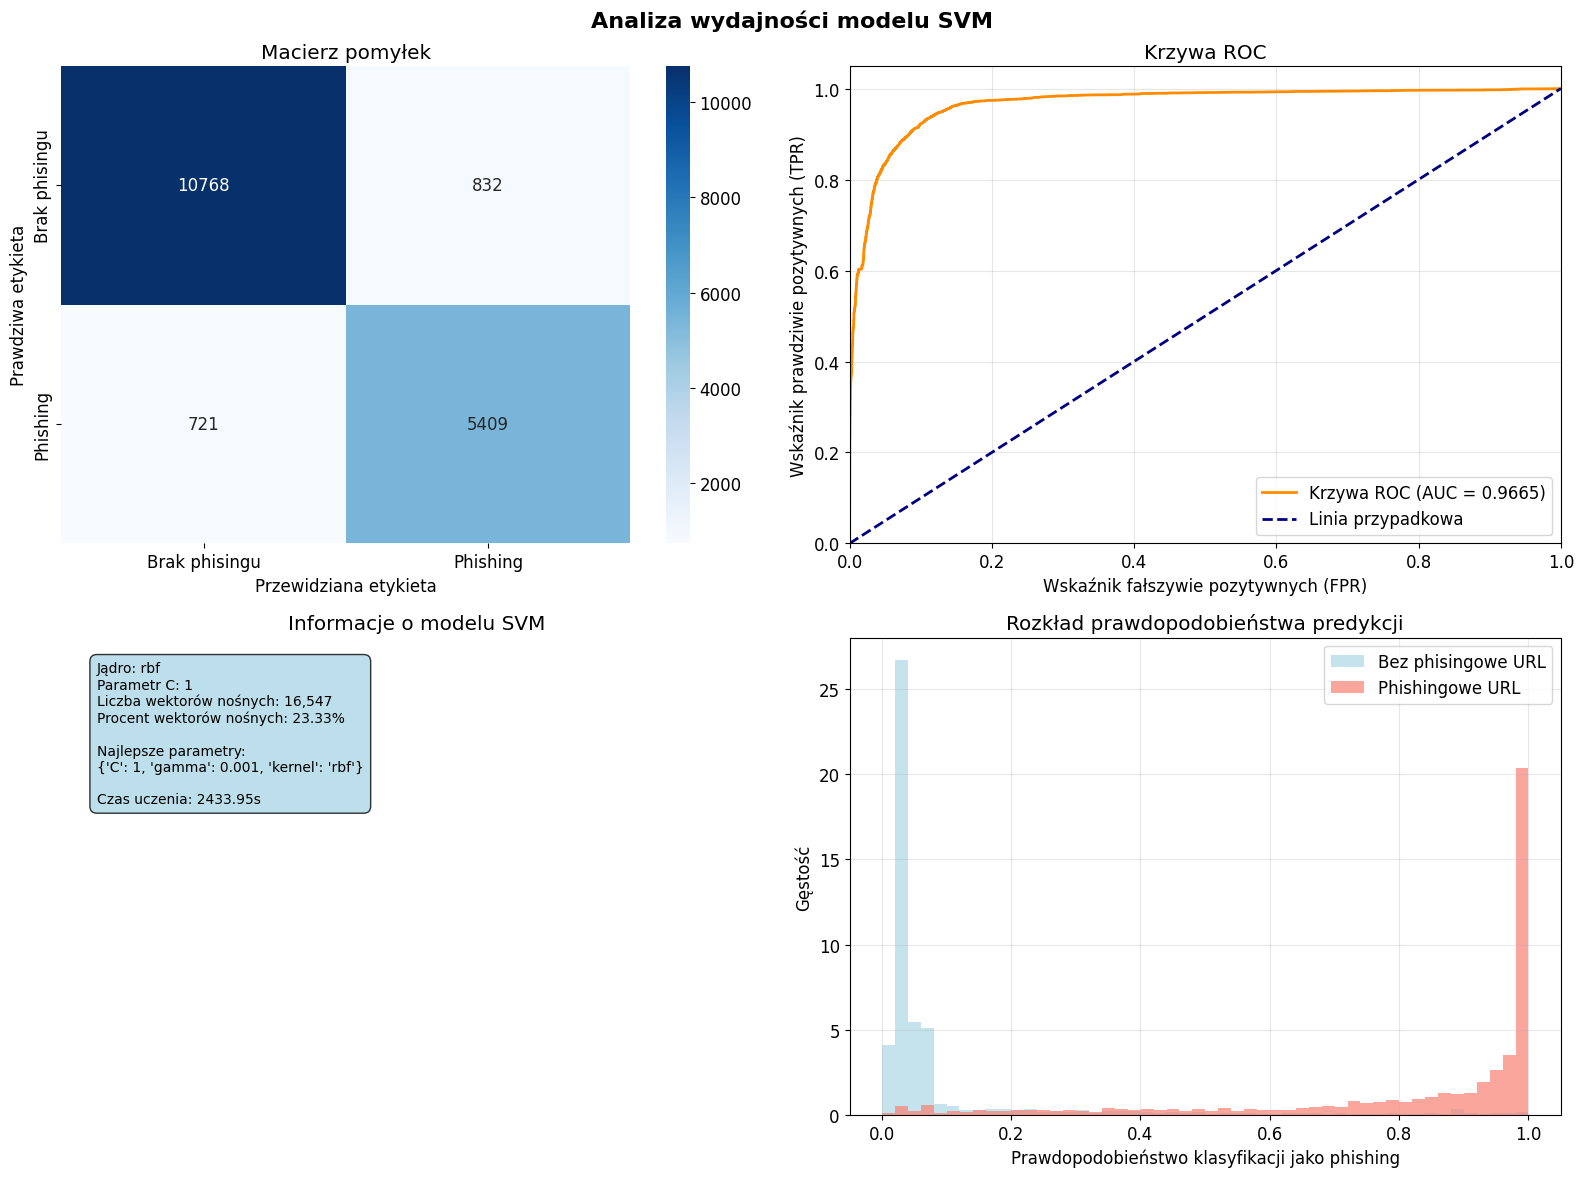


Wydajność modelu: BARDZO DOBRA


In [11]:

y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc_roc = roc_auc_score(y_test, y_pred_proba)

print("Przeprowadzanie walidacji krzyżowej...")
cv_scores = cross_val_score(best_model, X_train_scaled, y_train, cv=5, scoring='roc_auc')

print("\n" + "="*50)
print("="*50)
print(f"Dokładność:     {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precyzja:       {precision:.4f} ({precision*100:.2f}%)")
print(f"Czułość:        {recall:.4f} ({recall*100:.2f}%)")
print(f"Miara F1:       {f1:.4f}")
print(f"ROC-AUC:        {auc_roc:.4f}")
print(f"CV ROC-AUC:     {cv_scores.mean():.4f} (±{cv_scores.std()*2:.4f})")

target_names = ['Bez phisingowe URL', 'Phishingowe URL']
print(classification_report(y_test, y_pred, target_names=target_names))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"\nAnaliza macierzy pomyłek:")
print(f"  Prawdziwie negatywne (TN): {tn:,}")
print(f"  Fałszywie pozytywne (FP): {fp:,}")
print(f"  Fałszywie negatywne (FN): {fn:,}")
print(f"  Prawdziwie pozytywne (TP): {tp:,}")

if hasattr(best_model, 'n_support_'):
    total_support_vectors = best_model.n_support_.sum()
    support_vector_percentage = 100 * total_support_vectors / len(X_train_scaled)
    
    print(f"\nInformacje o modelu SVM:")
    print(f"  Jądro: {best_model.kernel}")
    print(f"  Parametr C: {best_model.C}")
    if hasattr(best_model, 'gamma'):
        print(f"  Parametr gamma: {best_model.gamma}")
    if hasattr(best_model, 'degree'):
        print(f"  Stopień wielomianu: {best_model.degree}")
    print(f"  Liczba wektorów nośnych: {total_support_vectors:,}")
    print(f"  Procent wektorów nośnych: {support_vector_percentage:.2f}%")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Analiza wydajności modelu SVM', fontsize=16, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Brak phisingu', 'Phishing'], 
            yticklabels=['Brak phisingu', 'Phishing'], 
            ax=axes[0,0])
axes[0,0].set_title('Macierz pomyłek')
axes[0,0].set_ylabel('Prawdziwa etykieta')
axes[0,0].set_xlabel('Przewidziana etykieta')

fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
axes[0,1].plot(fpr, tpr, color='darkorange', lw=2, 
               label=f'Krzywa ROC (AUC = {auc_roc:.4f})')
axes[0,1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', 
               label='Linia przypadkowa')
axes[0,1].set_xlim([0.0, 1.0])
axes[0,1].set_ylim([0.0, 1.05])
axes[0,1].set_xlabel('Wskaźnik fałszywie pozytywnych (FPR)')
axes[0,1].set_ylabel('Wskaźnik prawdziwie pozytywnych (TPR)')
axes[0,1].set_title('Krzywa ROC')
axes[0,1].legend(loc="lower right")
axes[0,1].grid(True, alpha=0.3)

info_text = f'''Jądro: {best_model.kernel}
Parametr C: {best_model.C}
Liczba wektorów nośnych: {total_support_vectors:,}
Procent wektorów nośnych: {support_vector_percentage:.2f}%

Najlepsze parametry:
{best_overall_params}

Czas uczenia: {final_training_time:.2f}s'''

axes[1,0].text(0.05, 0.95, info_text, ha='left', va='top', fontsize=10,
               bbox=dict(boxstyle='round,pad=0.5', facecolor='lightblue', alpha=0.8),
               transform=axes[1,0].transAxes)
axes[1,0].set_title('Informacje o modelu SVM')
axes[1,0].set_xlim(0, 1)
axes[1,0].set_ylim(0, 1)
axes[1,0].axis('off')

axes[1,1].hist(y_pred_proba[y_test == 0], bins=50, alpha=0.7, 
               label='Bez phisingowe URL', color='lightblue', density=True)
axes[1,1].hist(y_pred_proba[y_test == 1], bins=50, alpha=0.7, 
               label='Phishingowe URL', color='salmon', density=True)
axes[1,1].set_xlabel('Prawdopodobieństwo klasyfikacji jako phishing')
axes[1,1].set_ylabel('Gęstość')
axes[1,1].set_title('Rozkład prawdopodobieństwa predykcji')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()

plot_filename = f"{PLOTS_DIR}/svm_analysis.png"
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')

plt.show()

print(f"\n{'='*50}")
print(f"{'='*50}")

high_performance_metrics = [
    accuracy >= 0.95, 
    precision >= 0.95, 
    recall >= 0.95, 
    f1 >= 0.95, 
    auc_roc >= 0.95
]

if all(high_performance_metrics):
    performance_level = "DOSKONAŁA"
elif accuracy >= 0.90 and auc_roc >= 0.90:
    performance_level = "BARDZO DOBRA"
elif accuracy >= 0.85 and auc_roc >= 0.85:
    performance_level = "DOBRA"
else:
    performance_level = "WYMAGA POPRAWY"

print(f"Wydajność modelu: {performance_level}")

In [12]:

import pickle
import os

os.makedirs('../models', exist_ok=True)
os.makedirs('../data', exist_ok=True)

model_data = {
    'model': best_model,
    'scaler': scaler,  
    'feature_names': X.columns.tolist(),
    'best_params': best_overall_params,
    'metrics': {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc_roc': auc_roc,
        'cv_auc_mean': cv_scores.mean(),
        'cv_auc_std': cv_scores.std(),
        'support_vectors': best_model.n_support_.sum() if hasattr(best_model, 'n_support_') else None
    }
}

model_path = '../models/svm_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(model_data, f)

results_df = pd.DataFrame({
    'Metryka': ['Dokładność', 'Precyzja', 'Czułość', 'Miara F1', 'AUC-ROC'],
    'Wartość': [accuracy, precision, recall, f1, auc_roc]
})

results_path = '../data/svm_results.csv'
results_df.to_csv(results_path, index=False)

performance_summary = {
    'typ_modelu': 'SVM',
    'jądro': best_model.kernel,
    'dokładność': accuracy,
    'precyzja': precision,
    'czułość': recall,
    'miara_f1': f1,
    'roc_auc': auc_roc,
    'cv_auc_średnia': cv_scores.mean(),
    'cv_auc_odchylenie': cv_scores.std(),
    'liczba_cech': len(X.columns),
    'próbki_uczące': len(X_train_scaled),
    'próbki_testowe': len(X_test_scaled),
    'czas_strojenia': total_time,
    'najlepsza_konfiguracja': best_kernel_name,
    'wektory_nośne': best_model.n_support_.sum() if hasattr(best_model, 'n_support_') else 'N/A'
}

print(f"\n{'='*50}")
print(f"{'='*50}")
for key, value in performance_summary.items():
    if isinstance(value, float):
        print(f"{key.replace('_', ' ').title()}: {value:.4f}")
    else:
        print(f"{key.replace('_', ' ').title()}: {value}")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Brak phishingu', 'Phishing'], 
            yticklabels=['Brak phishingu', 'Phishing'])
plt.title('Macierz pomyłek - SVM')
plt.ylabel('Prawdziwa etykieta')
plt.xlabel('Przewidziana etykieta')
plt.savefig(f'{PLOTS_DIR}/svm_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.close()

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Krzywa ROC (AUC = {auc_roc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Wskaźnik fałszywie pozytywnych')
plt.ylabel('Wskaźnik prawdziwie pozytywnych')
plt.title('Krzywa ROC - SVM')
plt.legend(loc="lower right")
plt.savefig(f'{PLOTS_DIR}/svm_roc_curve.png', dpi=300, bbox_inches='tight')
plt.close()


Typ Modelu: SVM
Jądro: rbf
Dokładność: 0.9124
Precyzja: 0.8667
Czułość: 0.8824
Miara F1: 0.8745
Roc Auc: 0.9665
Cv Auc Średnia: 0.9681
Cv Auc Odchylenie: 0.0010
Liczba Cech: 100
Próbki Uczące: 70917
Próbki Testowe: 17730
Czas Strojenia: 7570.9926
Najlepsza Konfiguracja: Jądro RBF (radialne)
Wektory Nośne: 16547
